In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

# Paths
noisy_path = "/content/drive/MyDrive/Signal_denoising/ecg_signals_noisy_lot.csv"
clean_path = "/content/drive/MyDrive/Signal_denoising/ecg.csv"

# Load (no header, assume last column is class label)
noisy_df = pd.read_csv(noisy_path, header=None)
clean_df = pd.read_csv(clean_path, header=None)

print("===== Noisy File =====")
print("Shape:", noisy_df.shape)
print(noisy_df.head())
print("\nLabel distribution in noisy file:")
print(noisy_df.iloc[:, -1].value_counts())

print("\n===== Clean File =====")
print("Shape:", clean_df.shape)
print(clean_df.head())
print("\nLabel distribution in clean file:")
print(clean_df.iloc[:, -1].value_counts())

# Check if both datasets align
if noisy_df.shape == clean_df.shape:
    print("\nBoth datasets have the same shape ✅")
else:
    print("\n⚠️ Datasets differ in shape:", noisy_df.shape, clean_df.shape)

# Check if labels match exactly
label_match = np.all(noisy_df.iloc[:, -1].values == clean_df.iloc[:, -1].values)
print("Do the class labels match across files? ->", label_match)


===== Noisy File =====
Shape: (4998, 141)
        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.061546 -4.061422 -4.126505 -4.642597 -4.002707 -3.012498 -1.579330   
2 -0.625507 -2.448654 -3.969960 -4.574985 -4.218812 -2.968914 -1.806713   
3  0.584042 -1.991373 -3.538028 -4.355372 -4.112160 -3.806046 -3.030795   
4  0.887662 -0.842421 -2.332764 -3.899836 -4.380926 -3.656883 -2.521642   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -1.120649 -0.866896  0.177040  ...  0.498133  0.674112  0.651356  0.746809   
2 -1.465706 -1.106107 -0.608303  ...  0.859252  0.522799  0.167167 -0.177868   
3 -1.644904 -1.338716 -0.786224  ...  0.213062  0.557153  0.466554  1.015882   
4 -1.806133 -1.523906 -0.875841  ...  1.115446  0.822045  0.840638  1.344794   

        135       136     

Adding Synthetic Noise

In [6]:
import pandas as pd
import numpy as np

# Load clean ECG
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
df_clean = pd.read_csv(path_clean, header=None)

# Separate signals and labels
X_clean = df_clean.iloc[:, :-1].values
y = df_clean.iloc[:, -1].values

# Add Gaussian noise (adjust std dev for noise level)
noise_std = 0.5  # try 0.2 for mild noise, 0.5 for stronger, 1.0 for very noisy
noise = np.random.normal(0, noise_std, X_clean.shape)
X_noisy = X_clean + noise

# Recombine signals + labels
df_noisy = pd.DataFrame(np.hstack([X_noisy, y.reshape(-1, 1)]))

# Save noisy dataset
output_path = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"
df_noisy.to_csv(output_path, index=False, header=False)

print(f"Noisy ECG dataset saved at: {output_path}")


Noisy ECG dataset saved at: /content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv


Comparison Between Noisy and Clean

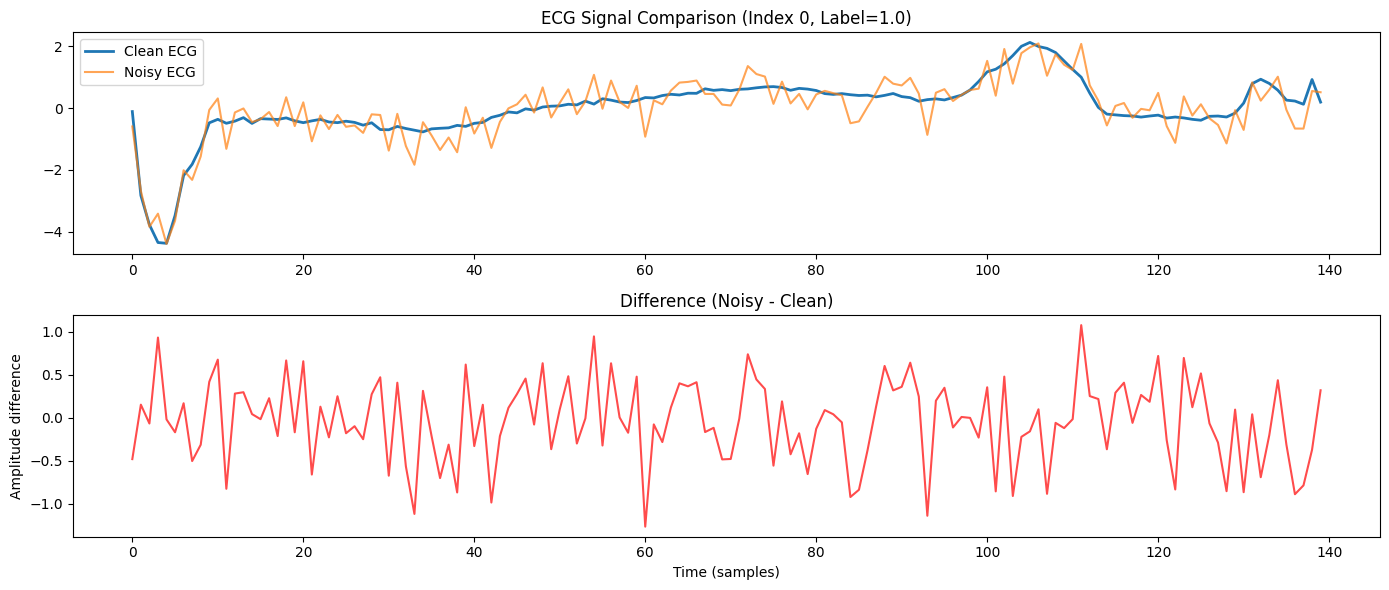

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Paths
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

# Load datasets
df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

# Separate signals and labels
X_clean = df_clean.iloc[:, :-1].values
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values
y_noisy = df_noisy.iloc[:, -1].values

# Pick one signal to visualize (e.g., index 0)
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_diff = signal_noisy - signal_clean

# Plot comparison
plt.figure(figsize=(14, 6))

# Clean vs Noisy
plt.subplot(2, 1, 1)
plt.plot(signal_clean, label="Clean ECG", linewidth=2)
plt.plot(signal_noisy, label="Noisy ECG", alpha=0.7)
plt.legend()
plt.title(f"ECG Signal Comparison (Index {idx}, Label={y_clean[idx]})")

# Difference plot
plt.subplot(2, 1, 2)
plt.plot(signal_diff, color="red", alpha=0.7)
plt.title("Difference (Noisy - Clean)")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude difference")

plt.tight_layout()
plt.show()


**Cleaning Techniques**



**Classical Signal Processing **



Method 1 - Butterworth low-pass filter

Metrics for Butterworth Denoising (Index 0):
MSE: 0.0631, RMSE: 0.2512, MAE: 0.2002, SNR: 11.97 dB, Correlation: 0.9686


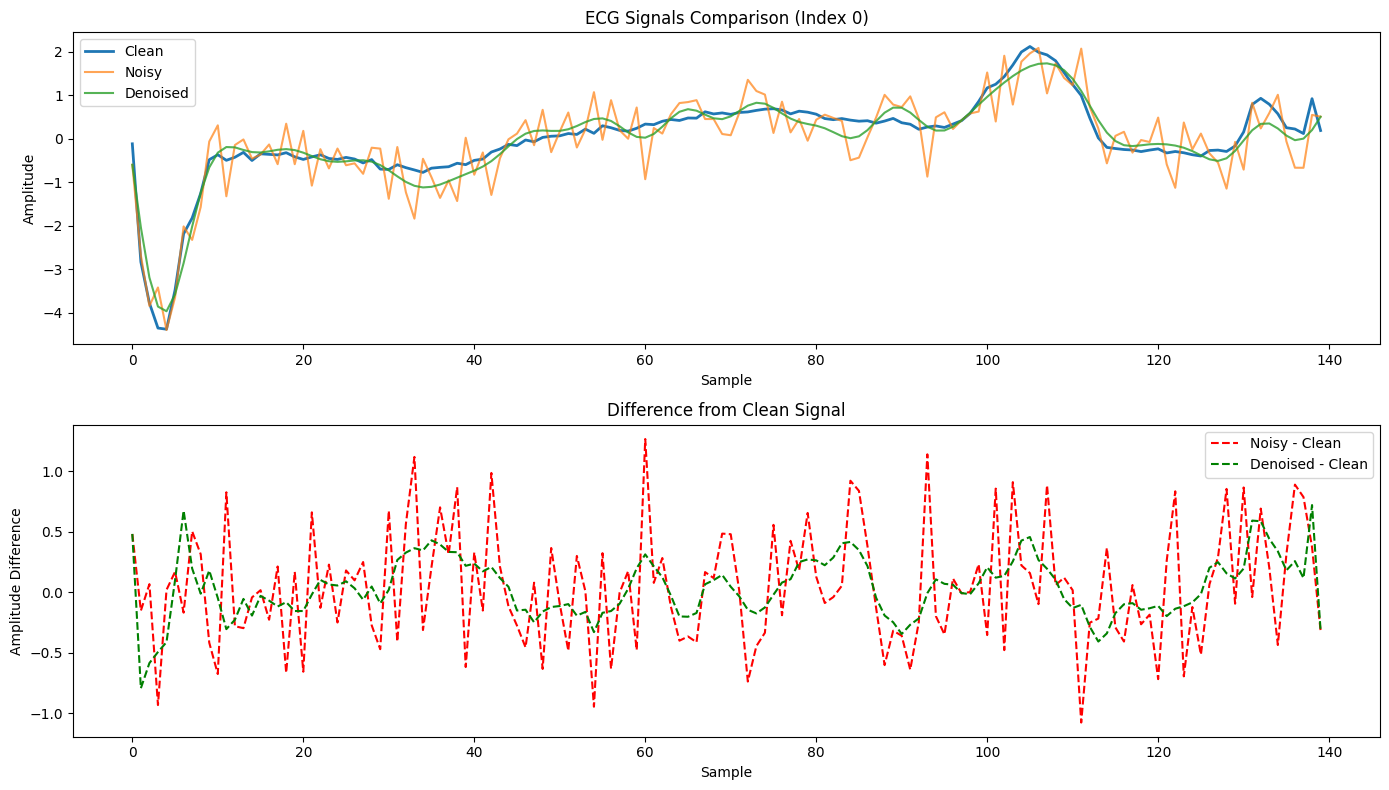

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values
y_noisy = df_noisy.iloc[:, -1].values

# --- Butterworth Low-pass Filter ---
def butter_lowpass_filter(signal, cutoff=40, fs=360, order=4):
    """
    cutoff: cutoff frequency in Hz
    fs: sampling frequency in Hz (ECG often sampled at 360 Hz)
    order: filter order
    """
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    filtered = filtfilt(b, a, signal)
    return filtered

# Apply filter to one example signal
idx = 0  # index of signal to denoise
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = butter_lowpass_filter(signal_noisy)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"Metrics for Butterworth Denoising (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

# Original vs Noisy vs Denoised
plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

# Difference plot (Clean - Denoised)
plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


Method 2 - Savitzky–Golay smoothing

Metrics for Savitzky–Golay Denoising (Index 0):
MSE: 0.0629, RMSE: 0.2509, MAE: 0.2035, SNR: 11.98 dB, Correlation: 0.9690


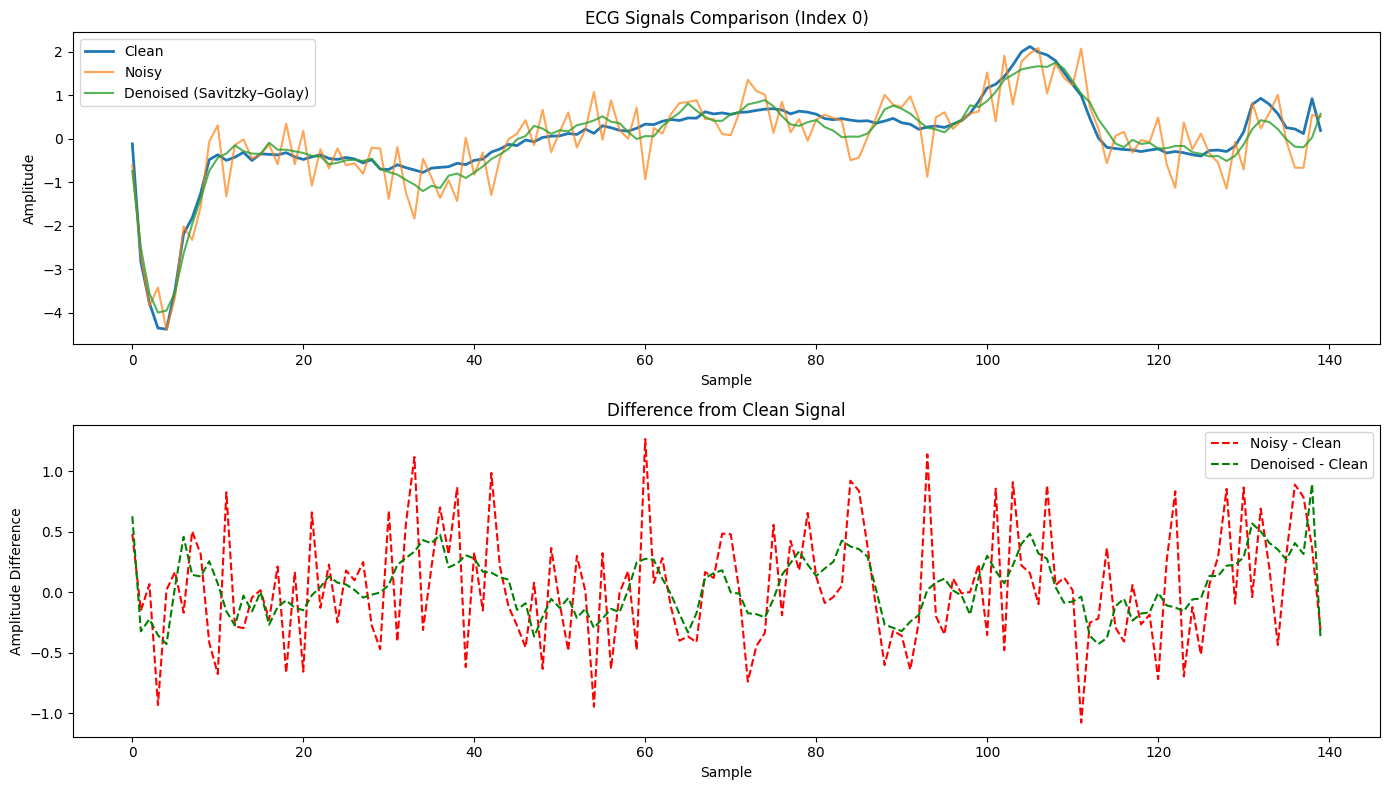

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.stats import pearsonr

# --- Load datasets (if not already loaded) ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values
y_noisy = df_noisy.iloc[:, -1].values

# --- Savitzky-Golay Filter ---
def sg_filter(signal, window_length=11, polyorder=3):
    """
    window_length: must be odd and > polyorder
    polyorder: polynomial order
    """
    return savgol_filter(signal, window_length=window_length, polyorder=polyorder)

# Apply filter to one example
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = sg_filter(signal_noisy, window_length=11, polyorder=3)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"Metrics for Savitzky–Golay Denoising (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

# Original vs Noisy vs Denoised
plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (Savitzky–Golay)', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

# Difference plot (Clean - Denoised)
plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


Method 3 - Wavelet Denoising

/usr/local/lib/python3.12/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 4 is too high: all coefficients will experience boundary effects.
  warnings.warn(


Wavelet Denoising Metrics (Index 0):
MSE: 0.2298, RMSE: 0.4794, MAE: 0.3603, SNR: 6.35 dB, Correlation: 0.8789


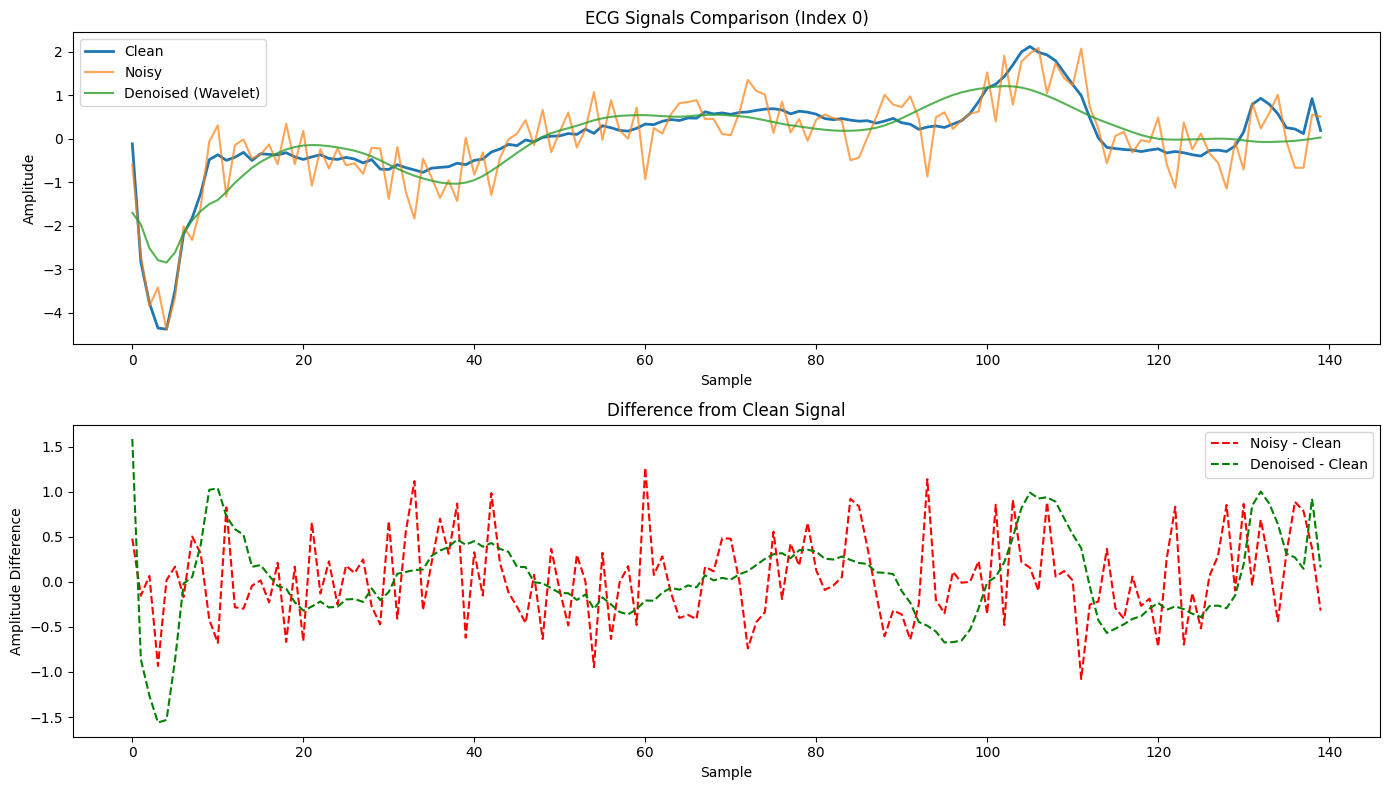

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values
y_noisy = df_noisy.iloc[:, -1].values

# --- Wavelet Denoising Function ---
def wavelet_denoise(signal, wavelet='db6', level=4):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    # Universal threshold
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(signal)))
    # Soft thresholding
    coeffs_thresh = [pywt.threshold(c, threshold, mode='soft') if i>0 else c for i, c in enumerate(coeffs)]
    return pywt.waverec(coeffs_thresh, wavelet)

# Apply Wavelet denoising to one example
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = wavelet_denoise(signal_noisy)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"Wavelet Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (Wavelet)', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


Method 4 - Empirical Mode Decomposition (EMD) denoising.

In [12]:
!pip install EMD-signal


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.3/82.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.3/150.3 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 4.7 MB/s eta 0:00:00
  Attempting uninstall: dill
    Found existing installation: dill 0.3.8
    Uninstalling dill-0.3.8:
      Successfully uninstalled dill-0.3.8
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.16
    Uninstalling multiprocess-0.70.16:
      Successfully uninstalled multiprocess-0.70.16
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.0.0 requires dill<0.3.9,>=0.3.0, but you have dill 0.4.0 which is incompatible.
datasets 4.0

EMD Denoising Metrics (Index 0):
MSE: 0.1248, RMSE: 0.3533, MAE: 0.2829, SNR: 9.01 dB, Correlation: 0.9372


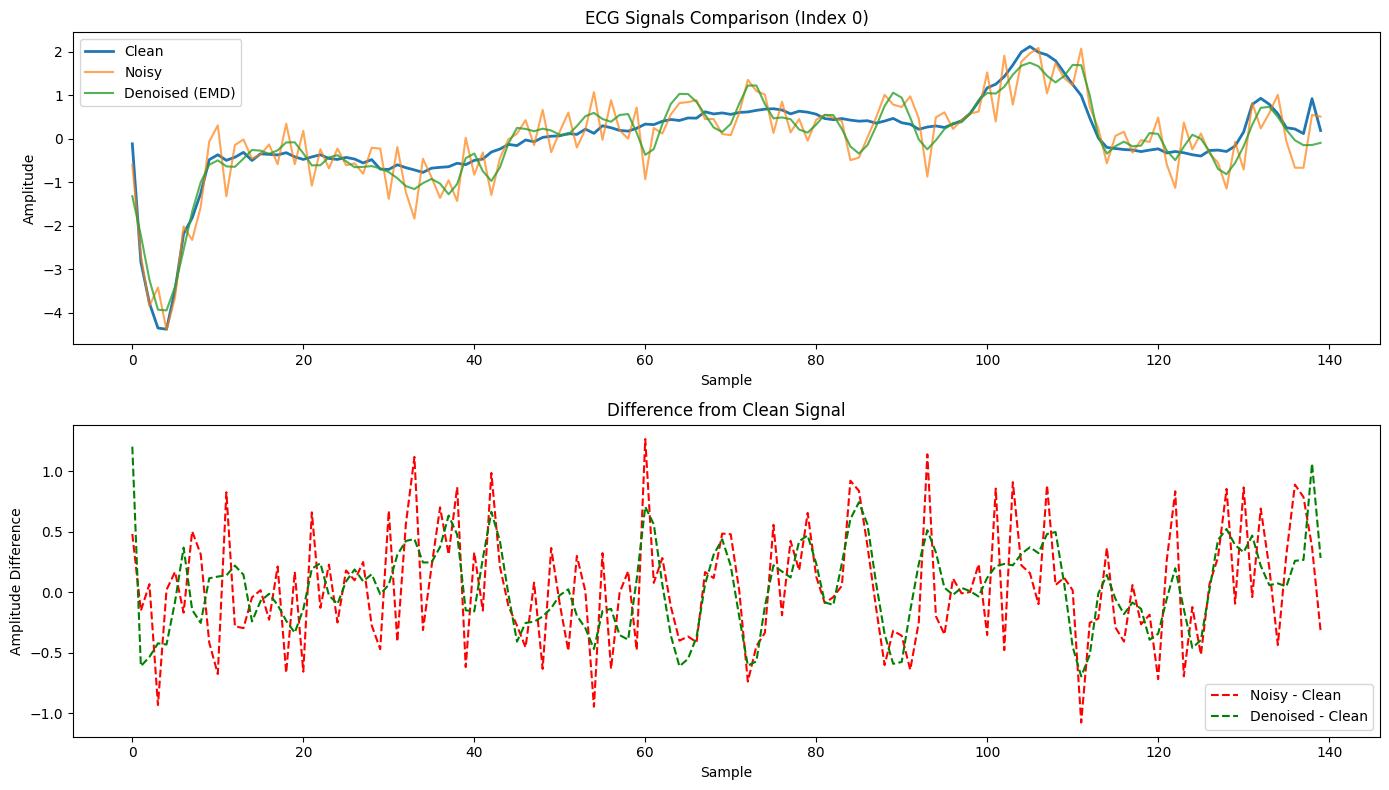

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PyEMD import EMD
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values
y_noisy = df_noisy.iloc[:, -1].values

# --- EMD Denoising Function ---
def emd_denoise(signal, num_imfs_to_remove=1):
    emd = EMD()
    imfs = emd(signal)
    # Reconstruct signal by removing first few IMFs (high-frequency noise)
    denoised = np.sum(imfs[num_imfs_to_remove:], axis=0)
    return denoised

# Apply EMD denoising to one example
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = emd_denoise(signal_noisy, num_imfs_to_remove=1)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"EMD Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (EMD)', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


**Optimization / Regularization**

Method 5 - Total Variation Denoising (TVD).

TVD Denoising Metrics (Index 0):
MSE: 0.1478, RMSE: 0.3844, MAE: 0.3054, SNR: 8.27 dB, Correlation: 0.9283


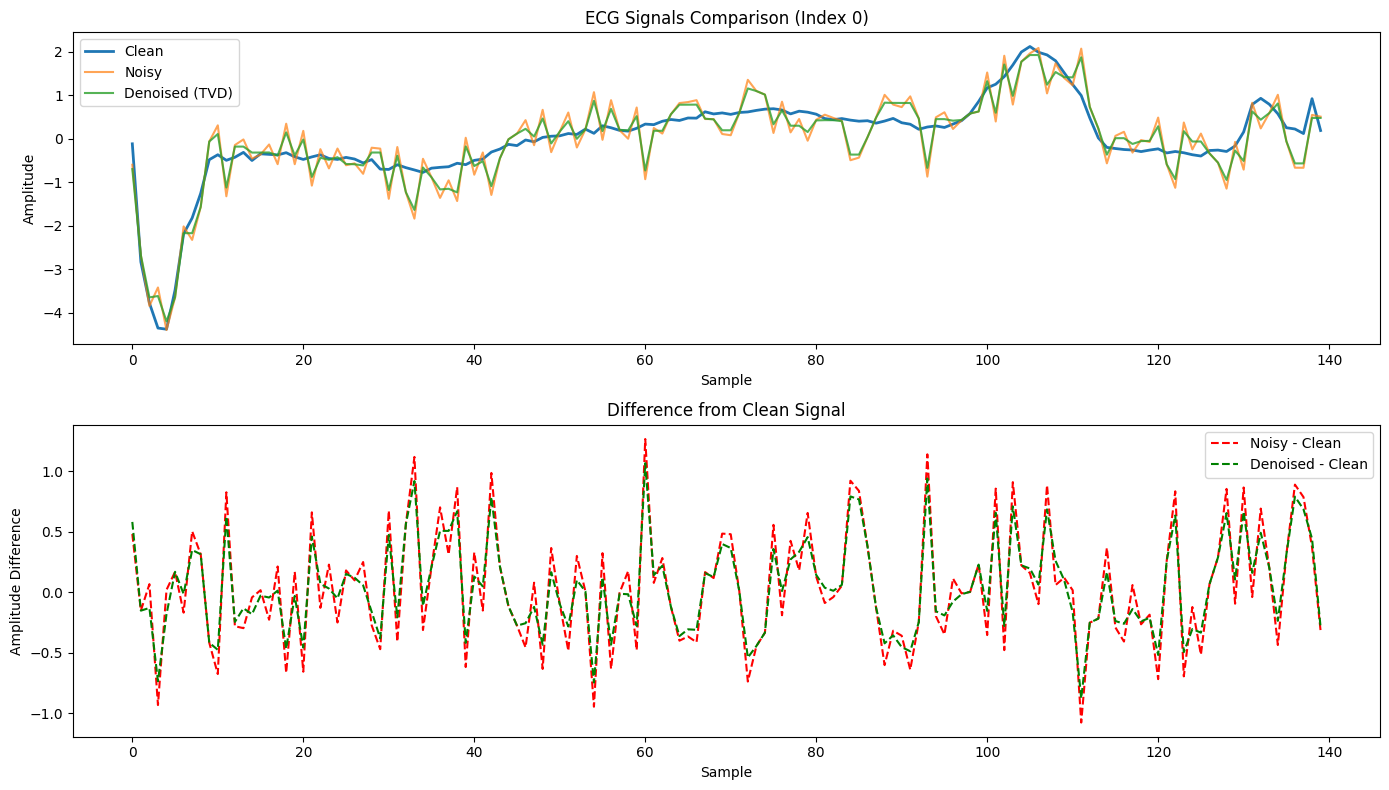

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skimage.restoration import denoise_tv_chambolle
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values
y_noisy = df_noisy.iloc[:, -1].values

# --- TVD Denoising Function ---
def tvd_denoise(signal, weight=0.1):
    """
    Total Variation Denoising for 1D signals.
    weight: regularization parameter; higher -> smoother signal
    """
    denoised = denoise_tv_chambolle(signal, weight=weight)
    return denoised

# Apply TVD to one example
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = tvd_denoise(signal_noisy, weight=0.1)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"TVD Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (TVD)', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


Method 6 - ADMM-based Total Variation Denoising

ADMM-TV Denoising Metrics (Index 0):
MSE: 0.1478, RMSE: 0.3844, MAE: 0.3054, SNR: 8.27 dB, Correlation: 0.9283


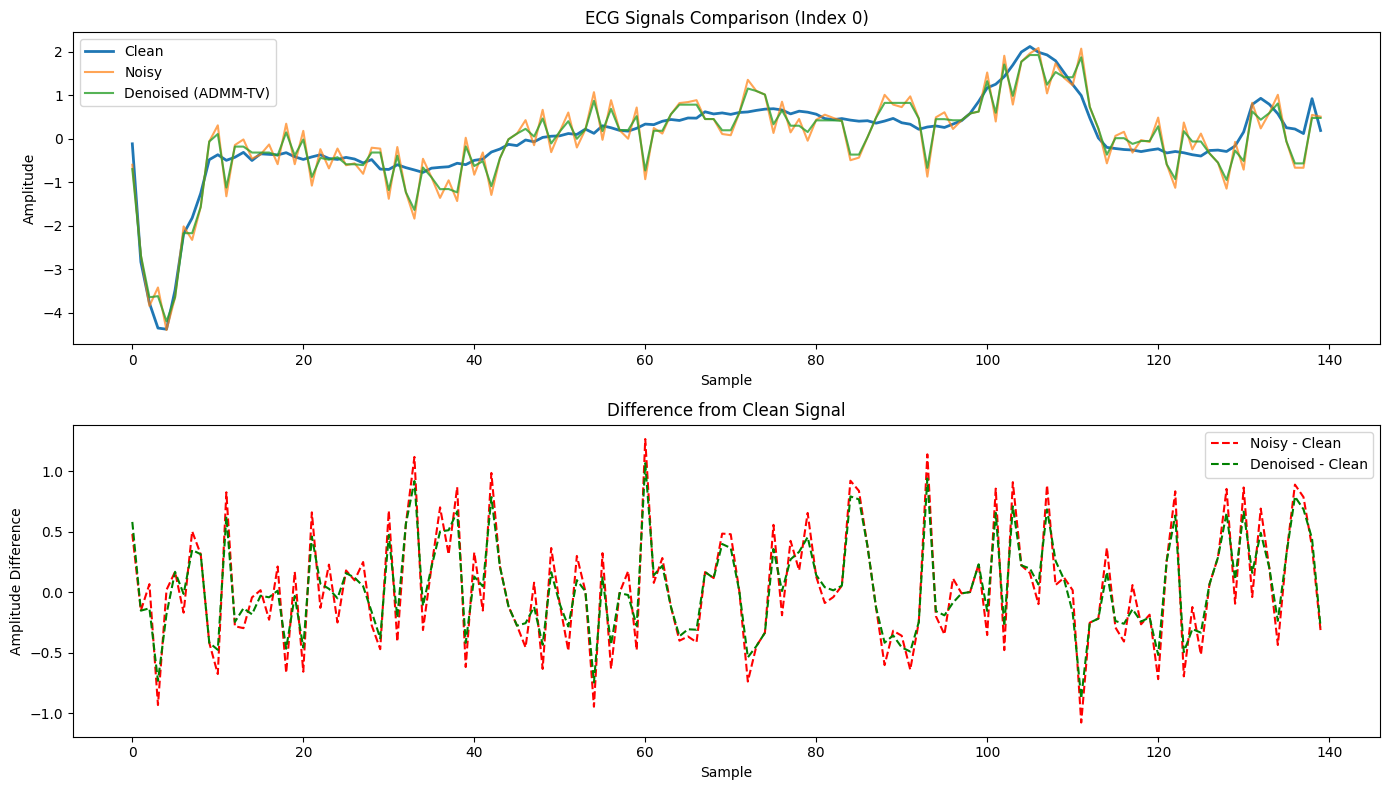

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values
y_noisy = df_noisy.iloc[:, -1].values

# --- ADMM TV Denoising Function ---
def admm_tvd(y, lam=0.1, rho=1.0, max_iter=100):
    """
    ADMM-based Total Variation Denoising
    y: noisy signal
    lam: regularization parameter (higher -> smoother)
    rho: ADMM penalty parameter
    """
    N = len(y)
    x = y.copy()
    z = np.zeros(N-1)
    u = np.zeros(N-1)

    # Difference operator
    D = np.eye(N-1, N, k=0) - np.eye(N-1, N, k=1)

    DtD = D.T @ D
    I = np.eye(N)

    for i in range(max_iter):
        # x-update: solve (I + rho*D^T D)x = y + rho*D^T(z-u)
        rhs = y + rho * D.T @ (z - u)
        x = np.linalg.solve(I + rho*DtD, rhs)

        # z-update: soft threshold
        Dx_plus_u = D @ x + u
        z = np.sign(Dx_plus_u) * np.maximum(np.abs(Dx_plus_u) - lam/rho, 0)

        # u-update
        u = u + D @ x - z

    return x

# Apply ADMM-TV to one example
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = admm_tvd(signal_noisy, lam=0.1, rho=1.0, max_iter=50)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"ADMM-TV Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (ADMM-TV)', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


Method 7 - ADMM with Wavelet Regularization

/tmp/ipython-input-1997378845.py:62: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(clean, denoised)


ADMM-Wavelet Denoising Metrics (Index 0):
MSE: 0.9929, RMSE: 0.9964, MAE: 0.6581, SNR: 0.00 dB, Correlation: nan


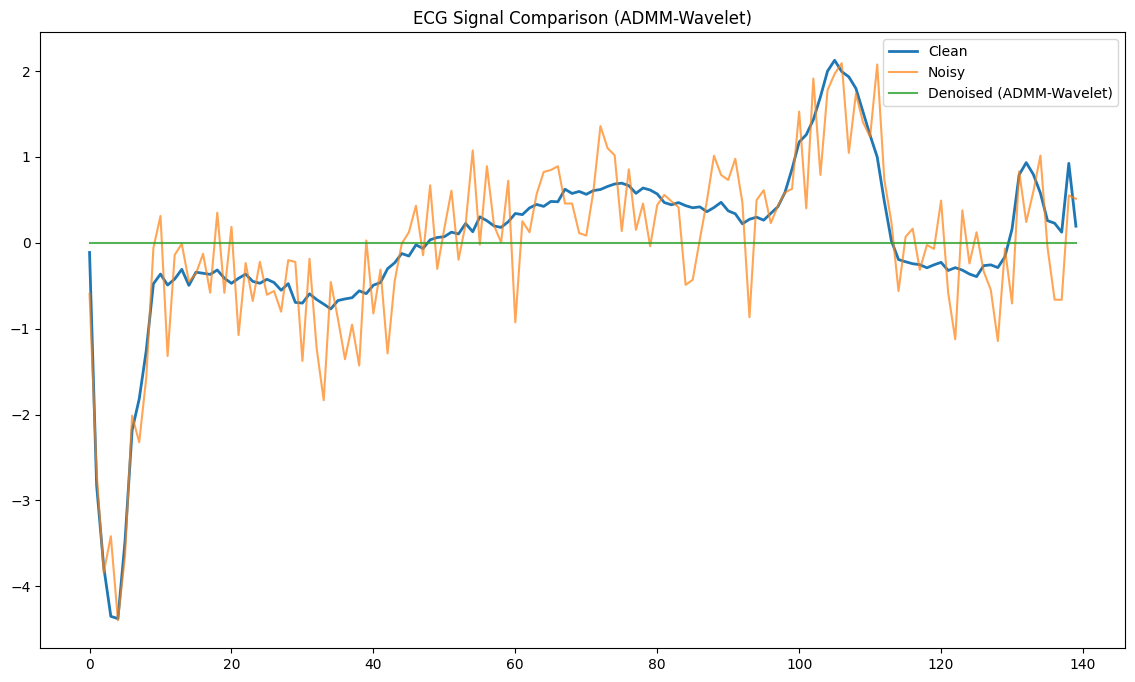

In [19]:
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values
X_noisy = df_noisy.iloc[:, :-1].values

# --- ADMM Wavelet Denoising ---
def admm_wavelet_denoise(y, wavelet='db4', level=4, lam=0.1, rho=1.0, max_iter=50):
    """
    y: noisy signal
    wavelet: type of wavelet
    level: decomposition level
    lam: regularization (sparsity) weight
    rho: ADMM penalty
    """
    # Wavelet decomposition
    coeffs = pywt.wavedec(y, wavelet, level=level)
    coeffs = [c.astype(float) for c in coeffs]
    x = y.copy()

    # Initialize z and u for all coeffs
    z_list = [np.zeros_like(c) for c in coeffs]
    u_list = [np.zeros_like(c) for c in coeffs]

    for _ in range(max_iter):
        # x-update: inverse wavelet using z-u
        temp_coeffs = [z - u for z, u in zip(z_list, u_list)]
        x = pywt.waverec(temp_coeffs, wavelet)
        x = x[:len(y)]  # truncate to original length

        # z-update: soft-threshold in wavelet domain
        coeffs_x = pywt.wavedec(x, wavelet, level=level)
        z_list = [np.sign(c + u) * np.maximum(np.abs(c + u) - lam/rho, 0) for c, u in zip(coeffs_x, u_list)]

        # u-update
        u_list = [u + c_x - z for u, c_x, z in zip(u_list, coeffs_x, z_list)]

    return x

# --- Apply to one example ---
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = admm_wavelet_denoise(signal_noisy, lam=0.05, rho=1.0)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"ADMM-Wavelet Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (ADMM-Wavelet)', alpha=0.8)
plt.legend()
plt.title("ECG Signal Comparison (ADMM-Wavelet)")
plt.show()


Method 8 - ADMM for Sparse Signal Denoising (L1 on differences)

ADMM-Sparse Denoising Metrics (Index 0):
MSE: 0.1846, RMSE: 0.4297, MAE: 0.3392, SNR: 7.31 dB, Correlation: 0.9127


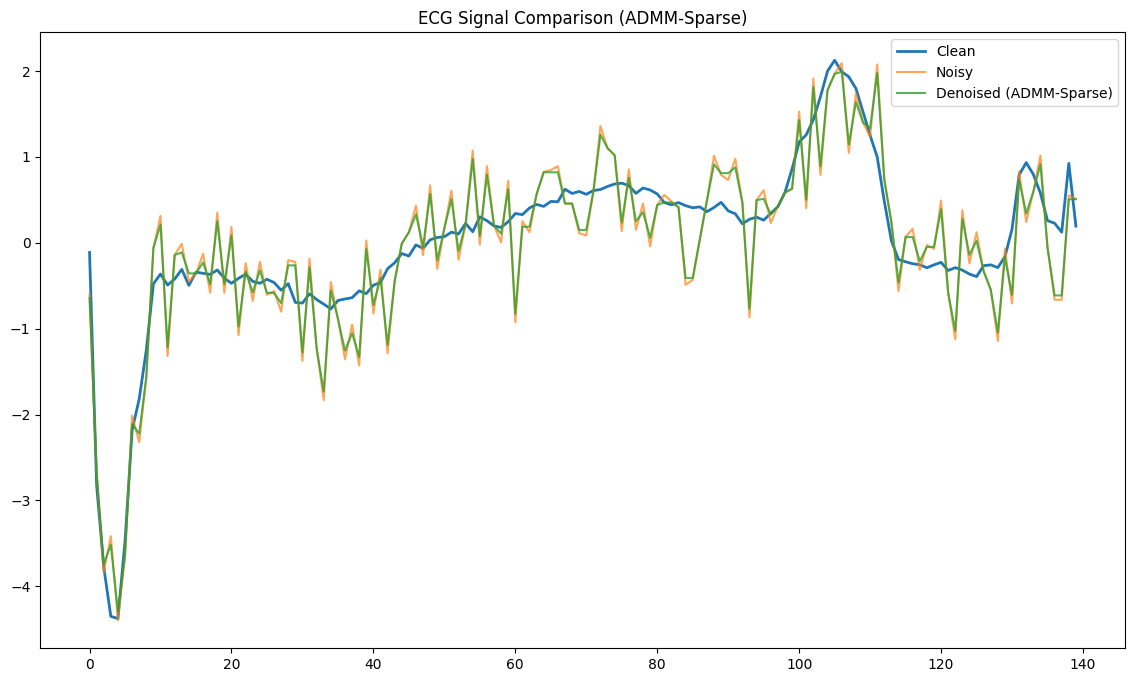

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- Load datasets ---
df_clean = pd.read_csv("/content/drive/MyDrive/Signal_denoising/ecg.csv", header=None)
df_noisy = pd.read_csv("/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv", header=None)

X_clean = df_clean.iloc[:, :-1].values
X_noisy = df_noisy.iloc[:, :-1].values

# --- ADMM Sparse Denoising ---
def admm_sparse_denoise(y, lam=0.1, rho=1.0, max_iter=50):
    N = len(y)
    x = y.copy()
    z = np.zeros(N-1)
    u = np.zeros(N-1)

    # Difference operator
    D = np.eye(N-1, N, k=0) - np.eye(N-1, N, k=1)
    DtD = D.T @ D
    I = np.eye(N)

    for _ in range(max_iter):
        rhs = y + rho * D.T @ (z - u)
        x = np.linalg.solve(I + rho*DtD, rhs)
        Dx_plus_u = D @ x + u
        z = np.sign(Dx_plus_u) * np.maximum(np.abs(Dx_plus_u) - lam/rho, 0)
        u = u + D @ x - z
    return x

# --- Apply to one example ---
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
signal_denoised = admm_sparse_denoise(signal_noisy, lam=0.05, rho=1.0)

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"ADMM-Sparse Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (ADMM-Sparse)', alpha=0.8)
plt.legend()
plt.title("ECG Signal Comparison (ADMM-Sparse)")
plt.show()


**Machine Learning Approaches**

Method 9 - Denoising Autoencoder (DAE)

Epoch 10/50, Loss: 0.034060
Epoch 20/50, Loss: 0.027115
Epoch 30/50, Loss: 0.024337
Epoch 40/50, Loss: 0.022504
Epoch 50/50, Loss: 0.020927
Autoencoder Denoising Metrics (Index 0):
MSE: 0.0172, RMSE: 0.1311, MAE: 0.0948, SNR: 17.62 dB, Correlation: 0.9929


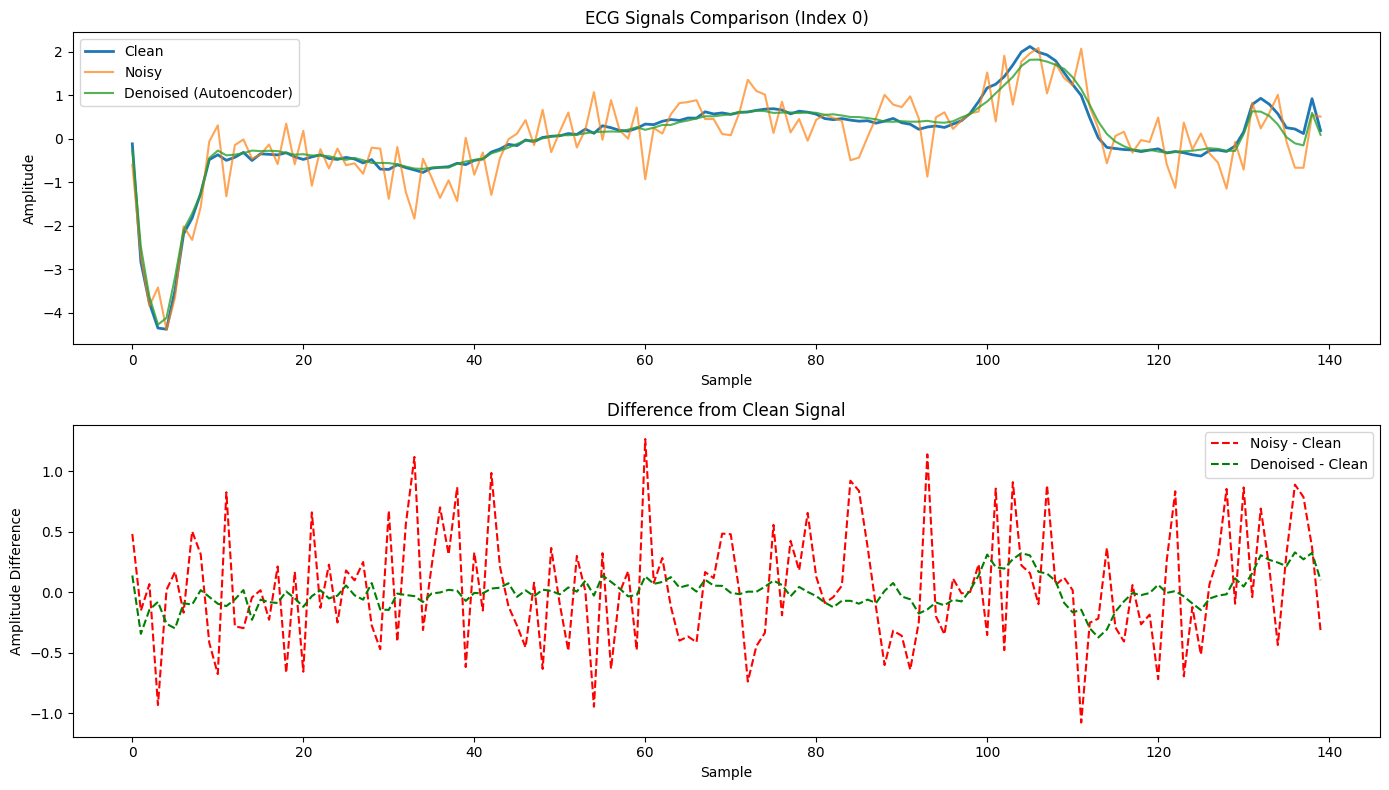

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values.astype(np.float32)
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values.astype(np.float32)
y_noisy = df_noisy.iloc[:, -1].values

# --- PyTorch Dataset ---
class ECGDataset(Dataset):
    def __init__(self, noisy, clean):
        self.noisy = torch.tensor(noisy)
        self.clean = torch.tensor(clean)
    def __len__(self):
        return len(self.noisy)
    def __getitem__(self, idx):
        return self.noisy[idx], self.clean[idx]

dataset = ECGDataset(X_noisy, X_clean)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# --- Autoencoder Model ---
class DenoisingAutoencoder(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, input_size)
        )
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

input_size = X_noisy.shape[1]
model = DenoisingAutoencoder(input_size)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- Train Autoencoder ---
epochs = 50
for epoch in range(epochs):
    running_loss = 0
    for noisy_batch, clean_batch in loader:
        optimizer.zero_grad()
        outputs = model(noisy_batch)
        loss = criterion(outputs, clean_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(loader):.6f}")

# --- Denoise one example ---
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
with torch.no_grad():
    signal_denoised = model(torch.tensor(signal_noisy)).numpy()

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"Autoencoder Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (Autoencoder)', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


Method 10 - 1D CNN Denoiser

Epoch 10/50, Loss: 0.047287
Epoch 20/50, Loss: 0.046659
Epoch 30/50, Loss: 0.046295
Epoch 40/50, Loss: 0.045972
Epoch 50/50, Loss: 0.045810
1D CNN Denoising Metrics (Index 0):
MSE: 0.0406, RMSE: 0.2015, MAE: 0.1516, SNR: 13.88 dB, Correlation: 0.9815


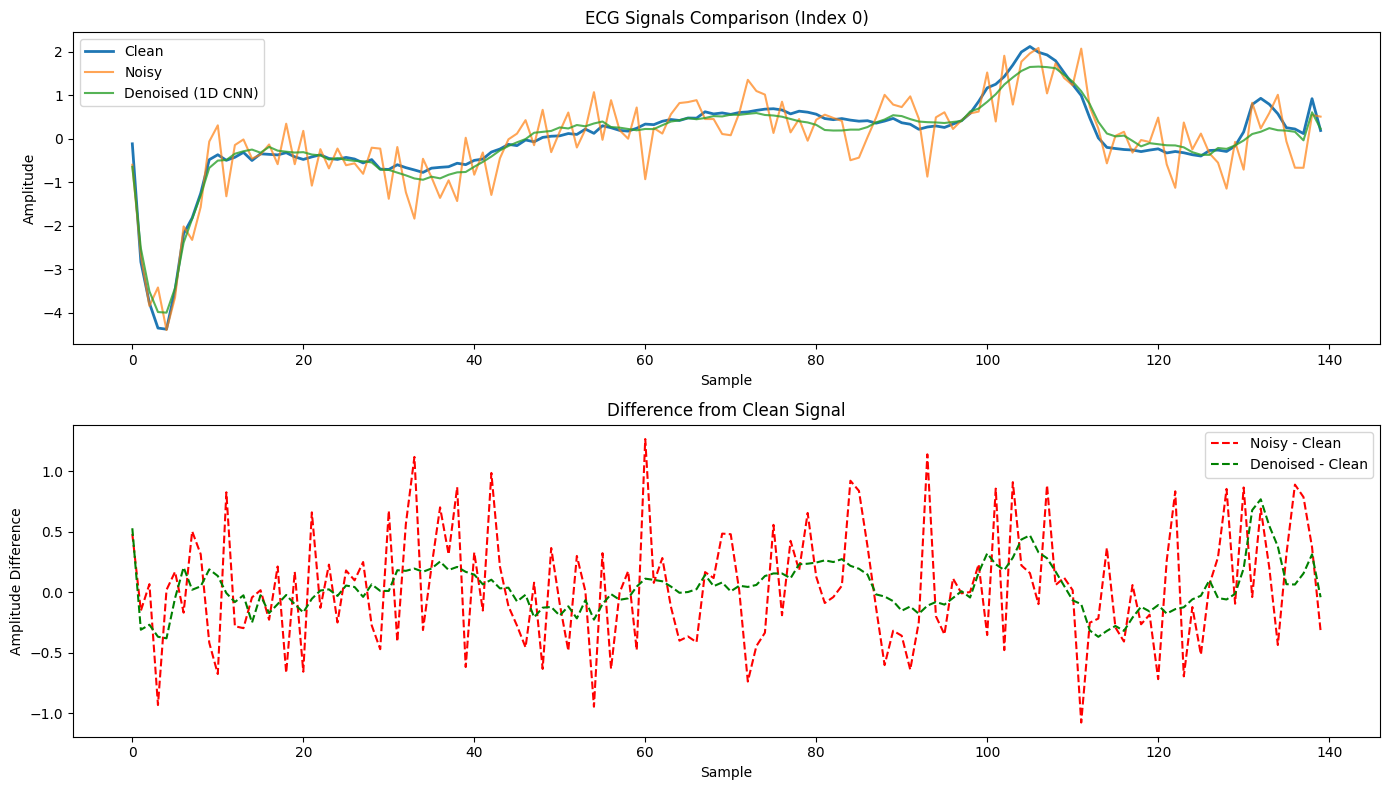

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from scipy.stats import pearsonr

# --- Load datasets ---
path_clean = "/content/drive/MyDrive/Signal_denoising/ecg.csv"
path_noisy = "/content/drive/MyDrive/Signal_denoising/ecg_noisy_generated.csv"

df_clean = pd.read_csv(path_clean, header=None)
df_noisy = pd.read_csv(path_noisy, header=None)

X_clean = df_clean.iloc[:, :-1].values.astype(np.float32)
y_clean = df_clean.iloc[:, -1].values

X_noisy = df_noisy.iloc[:, :-1].values.astype(np.float32)
y_noisy = df_noisy.iloc[:, -1].values

# --- PyTorch Dataset ---
class ECGDataset(Dataset):
    def __init__(self, noisy, clean):
        self.noisy = torch.tensor(noisy).unsqueeze(1)  # add channel dim
        self.clean = torch.tensor(clean).unsqueeze(1)
    def __len__(self):
        return len(self.noisy)
    def __getitem__(self, idx):
        return self.noisy[idx], self.clean[idx]

dataset = ECGDataset(X_noisy, X_clean)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# --- 1D CNN Denoiser Model ---
class CNN1DDenoiser(nn.Module):
    def __init__(self, input_len):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 16, kernel_size=3, padding=1),
            nn.ReLU()
        )
        self.decoder = nn.Conv1d(16, 1, kernel_size=3, padding=1)
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

input_len = X_noisy.shape[1]
model = CNN1DDenoiser(input_len)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- Train CNN Denoiser ---
epochs = 50
for epoch in range(epochs):
    running_loss = 0
    for noisy_batch, clean_batch in loader:
        optimizer.zero_grad()
        outputs = model(noisy_batch)
        loss = criterion(outputs, clean_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(loader):.6f}")

# --- Denoise one example ---
idx = 0
signal_clean = X_clean[idx]
signal_noisy = X_noisy[idx]
with torch.no_grad():
    signal_denoised = model(torch.tensor(signal_noisy).unsqueeze(0).unsqueeze(0)).squeeze().numpy()

# --- Metrics ---
def compute_metrics(clean, denoised):
    mse = np.mean((clean - denoised)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(clean - denoised))
    snr = 10 * np.log10(np.sum(clean**2) / np.sum((clean - denoised)**2))
    corr, _ = pearsonr(clean, denoised)
    return mse, rmse, mae, snr, corr

mse, rmse, mae, snr, corr = compute_metrics(signal_clean, signal_denoised)
print(f"1D CNN Denoising Metrics (Index {idx}):")
print(f"MSE: {mse:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}, SNR: {snr:.2f} dB, Correlation: {corr:.4f}")

# --- Plot signals ---
plt.figure(figsize=(14,8))

plt.subplot(2,1,1)
plt.plot(signal_clean, label='Clean', linewidth=2)
plt.plot(signal_noisy, label='Noisy', alpha=0.7)
plt.plot(signal_denoised, label='Denoised (1D CNN)', alpha=0.8)
plt.title(f"ECG Signals Comparison (Index {idx})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()

plt.subplot(2,1,2)
plt.plot(signal_clean - signal_noisy, label='Noisy - Clean', linestyle='--', color='red')
plt.plot(signal_clean - signal_denoised, label='Denoised - Clean', linestyle='--', color='green')
plt.title("Difference from Clean Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude Difference")
plt.legend()

plt.tight_layout()
plt.show()


COMPARISON

===== Metrics Table =====
           Method     MSE    RMSE     MAE  SNR (dB)  Correlation
0     Butterworth  0.0631  0.2512  0.2002     11.97       0.9686
1  Savitzky–Golay  0.0629  0.2509  0.2035     11.98       0.9690
2         Wavelet  0.2298  0.4794  0.3603      6.35       0.8789
3             EMD  0.1248  0.3533  0.2829      9.01       0.9372
4             TVD  0.1478  0.3844  0.3054      8.27       0.9283
5         ADMM-TV  0.1478  0.3844  0.3054      8.27       0.9283
6    ADMM-Wavelet  0.9929  0.9964  0.6581      0.00          NaN
7     ADMM-Sparse  0.1846  0.4297  0.3392      7.31       0.9127
8     Autoencoder  0.0172  0.1311  0.0948     17.62       0.9929
9          1D CNN  0.0406  0.2015  0.1516     13.88       0.9815


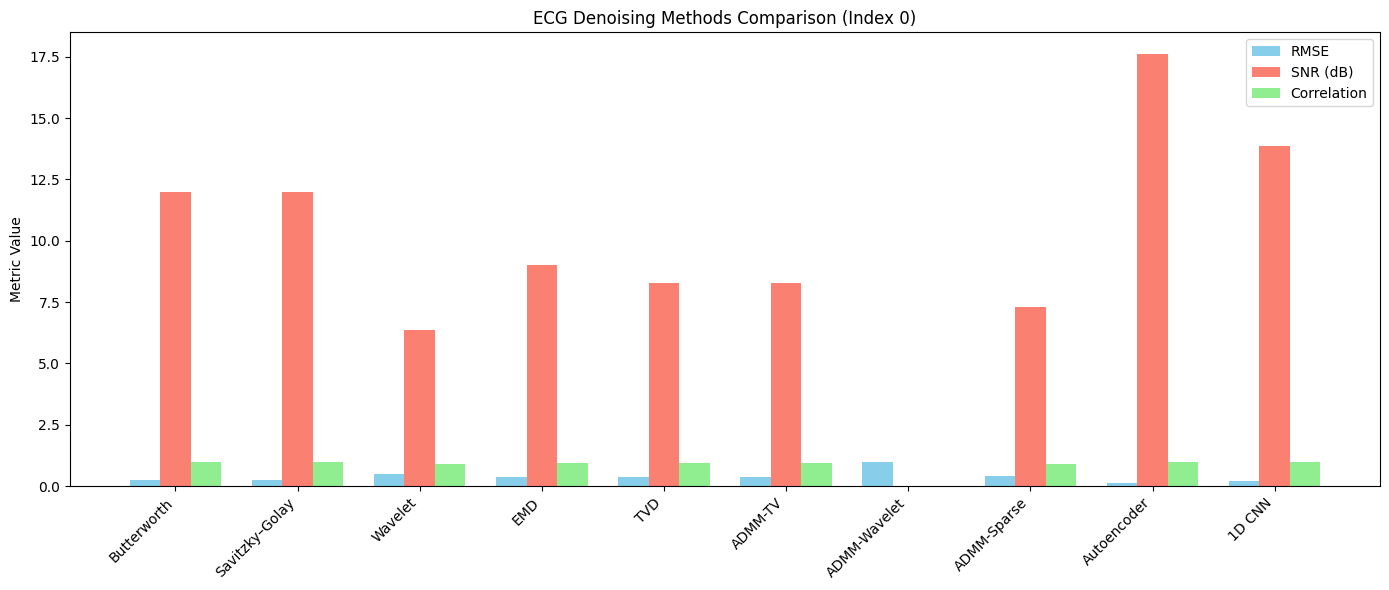


===== Method Rankings =====

Top Methods by RMSE:
           Method    RMSE
8     Autoencoder  0.1311
9          1D CNN  0.2015
1  Savitzky–Golay  0.2509

Top Methods by SNR (dB):
           Method  SNR (dB)
8     Autoencoder     17.62
9          1D CNN     13.88
1  Savitzky–Golay     11.98

Top Methods by Correlation:
           Method  Correlation
8     Autoencoder       0.9929
9          1D CNN       0.9815
1  Savitzky–Golay       0.9690


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Metrics Data ---
methods = ["Butterworth","Savitzky–Golay","Wavelet","EMD","TVD",
           "ADMM-TV","ADMM-Wavelet","ADMM-Sparse","Autoencoder","1D CNN"]

MSE = [0.0631,0.0629,0.2298,0.1248,0.1478,0.1478,0.9929,0.1846,0.0172,0.0406]
RMSE = [0.2512,0.2509,0.4794,0.3533,0.3844,0.3844,0.9964,0.4297,0.1311,0.2015]
MAE = [0.2002,0.2035,0.3603,0.2829,0.3054,0.3054,0.6581,0.3392,0.0948,0.1516]
SNR = [11.97,11.98,6.35,9.01,8.27,8.27,0.00,7.31,17.62,13.88]
CORR = [0.9686,0.9690,0.8789,0.9372,0.9283,0.9283,np.nan,0.9127,0.9929,0.9815]

# --- Create Metrics DataFrame ---
df_metrics = pd.DataFrame({
    "Method": methods,
    "MSE": MSE,
    "RMSE": RMSE,
    "MAE": MAE,
    "SNR (dB)": SNR,
    "Correlation": CORR
})

print("===== Metrics Table =====")
print(df_metrics)

# --- Plot Comparison: RMSE, SNR, Correlation ---
x = np.arange(len(methods))
width = 0.25

plt.figure(figsize=(14,6))
plt.bar(x - width, RMSE, width, label='RMSE', color='skyblue')
plt.bar(x, SNR, width, label='SNR (dB)', color='salmon')
plt.bar(x + width, CORR, width, label='Correlation', color='lightgreen')
plt.xticks(x, methods, rotation=45, ha='right')
plt.ylabel("Metric Value")
plt.title("ECG Denoising Methods Comparison (Index 0)")
plt.legend()
plt.tight_layout()
plt.show()

# --- Rank Methods ---
print("\n===== Method Rankings =====")

# Lower is better for MSE, RMSE, MAE; Higher is better for SNR, Correlation
metrics_to_rank = ["RMSE","SNR (dB)","Correlation"]
for metric in metrics_to_rank:
    if metric in ["RMSE"]:  # lower is better
        ranked = df_metrics.sort_values(by=metric, ascending=True)
    else:  # higher is better
        ranked = df_metrics.sort_values(by=metric, ascending=False)
    print(f"\nTop Methods by {metric}:")
    print(ranked[["Method", metric]].head(3))
